# Deep Reinforcement Learning: Multi-Armed Bandit Simulation
**BITS Pilani – M.Tech AI & ML | Assignment 1 | Group 132**

**Group Members:**
* Sriman Saswat Suvankar (2025AG05568)
* Anshuman Behera (2025AG05603)
* Saumyajeet Mohanty (2025AG05436)
* Swathika R (2025AG05924)

## 1. Problem Statement
The paper *"A Survey on Practical Applications of Multi-Armed and Contextual Bandits"* highlights how bandit algorithms resolve the **exploration vs. exploitation dilemma** across domains like healthcare and finance. To validate the mathematical mechanics of the algorithms surveyed, we simulate a **$K$-armed Bernoulli Bandit** environment.

At each time step $t$, the agent pulls one of $K$ arms and receives a stochastic binary reward $R_t \in \{0, 1\}$. The agent's goal is to minimize **Cumulative Regret**, defined as the cumulative difference between the reward generated by the optimal arm and the reward generated by the agent's actual choices.

## 1.1 Data Generation & Theoretical Assumptions

Since the survey evaluates algorithms across various domains, we isolate their core mathematical mechanics using **synthetic data generation** rather than relying on a domain-specific dataset. This ensures a clean, reproducible, and fair comparative analysis.

**Data Generation Process:**
*   **Synthetic Environment:** We construct a 5-armed bandit environment where each arm represents a distinct action (e.g., a specific medical treatment or a financial portfolio).
*   **Reward Distribution:** The environment yields stochastic, binary outcomes. When an arm is pulled, it returns a reward of $1$ (success) or $0$ (failure) based on a hidden Bernoulli probability unique to that arm.
*   **Initialization:** True success probabilities for the 5 arms are randomly initialized from a Uniform distribution $\sim U(0.1, 0.9)$.

**Underlying Assumptions:**
To scope the simulation, we make the following standard mathematical assumptions:
1.  **Stationarity:** The hidden probability distributions of the arms remain constant over time (no concept drift).
2.  **I.I.D. Rewards:** The rewards generated by pulling an arm are independent and identically distributed.
3.  **Context-Free Framework:** We assume a standard Multi-Armed Bandit (MAB) setting where the agent has no prior context or feature vectors about the environment before making a decision.
4.  **Instantaneous Feedback:** The agent observes the reward immediately after pulling an arm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Presentation-quality plot styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16

class BernoulliBandit:
    """A K-armed bandit with hidden Bernoulli reward probabilities."""
    def __init__(self, n_arms=5, seed=42):
        np.random.seed(seed)
        self.n_arms = n_arms
        self.true_probs = np.random.uniform(0.1, 0.9, n_arms)
        self.optimal_arm = np.argmax(self.true_probs)
        self.max_prob = np.max(self.true_probs)
        print(f"Environment: {n_arms} Arms | Optimal Arm: {self.optimal_arm} (Prob: {self.max_prob:.3f})")

    def pull(self, action):
        return 1 if np.random.rand() < self.true_probs[action] else 0

class BanditAgent:
    """Base modular agent class."""
    def __init__(self, n_arms):
        self.n_arms = n_arms
        self.counts = np.zeros(n_arms)
        self.q_values = np.zeros(n_arms)

    def update(self, action, reward):
        self.counts[action] += 1
        self.q_values[action] += (reward - self.q_values[action]) / self.counts[action]

def run_simulation(env_class, agent_class, agent_kwargs, steps=2000, trials=100):
    """Executes the simulation across multiple trials to average out stochastic noise."""
    n_arms = env_class().n_arms
    avg_regrets = np.zeros(steps)

    for trial in range(trials):
        env = env_class(n_arms=n_arms, seed=trial)
        agent = agent_class(n_arms=n_arms, **agent_kwargs)
        cumulative_regret = 0

        for t in range(steps):
            action = agent.select_action(t)
            reward = env.pull(action)
            agent.update(action, reward)

            # Calculate instantaneous regret
            cumulative_regret += (env.max_prob - env.true_probs[action])
            avg_regrets[t] += cumulative_regret

    return avg_regrets / trials

# Global simulation parameters
STEPS = 2000
TRIALS = 50
time_steps = np.arange(1, STEPS + 1)

## Algorithm 1: $\varepsilon$-Greedy Simulation
Explores a random arm with probability $\varepsilon$, and exploits the best-known arm with probability $1 - \varepsilon$.
$$A_t = \begin{cases} \arg\max_a Q_t(a) & \text{with probability } 1 - \varepsilon \\ \text{Random Arm} & \text{with probability } \varepsilon \end{cases}$$

Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.861)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.672)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.676)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.540)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.814)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.878)
Environment: 5 Arms | Optimal Arm: 3 (Prob: 0.835)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.814)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.882)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.875)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.501)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.717)
Environment: 5 Arms | Optimal Arm: 3 (Prob: 0.680)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.692)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.878)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.796)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.779)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.541)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.730)
Environment: 5 Arms | Optimal A

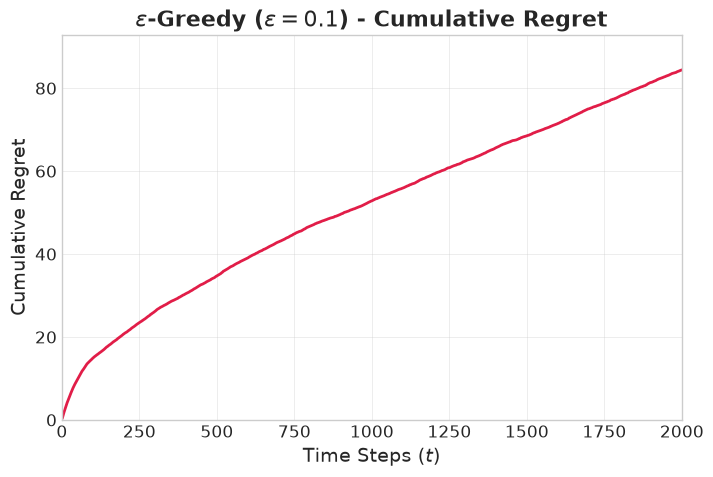

In [2]:
class EpsilonGreedyAgent(BanditAgent):
    def __init__(self, n_arms, epsilon=0.1):
        super().__init__(n_arms)
        self.epsilon = epsilon

    def select_action(self, step):
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.n_arms)
        return np.argmax(self.q_values)

# Execute and Plot
regret_eps = run_simulation(BernoulliBandit, EpsilonGreedyAgent, {'epsilon': 0.1}, STEPS, TRIALS)

plt.figure(figsize=(8, 5))
plt.plot(time_steps, regret_eps, color='#e11d48', linewidth=2)
plt.title(r'$\varepsilon$-Greedy ($\varepsilon=0.1$) - Cumulative Regret', fontweight='bold')
plt.xlabel('Time Steps ($t$)')
plt.ylabel('Cumulative Regret')
plt.xlim(0, STEPS)
plt.ylim(0, max(regret_eps) * 1.1)
plt.savefig('algo_1_eps_greedy.png', dpi=300, bbox_inches='tight')
plt.show()

## Algorithm 2: UCB1 Simulation
Deterministically selects arms by balancing the empirical mean reward against a logarithmic exploration bound.
$$A_t = \arg\max_a \left[ Q_t(a) + c \sqrt{\frac{\ln(t)}{N_t(a)}} \right]$$

Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.861)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.672)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.676)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.540)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.814)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.878)
Environment: 5 Arms | Optimal Arm: 3 (Prob: 0.835)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.814)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.882)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.875)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.501)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.717)
Environment: 5 Arms | Optimal Arm: 3 (Prob: 0.680)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.692)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.878)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.796)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.779)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.541)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.730)
Environment: 5 Arms | Optimal A

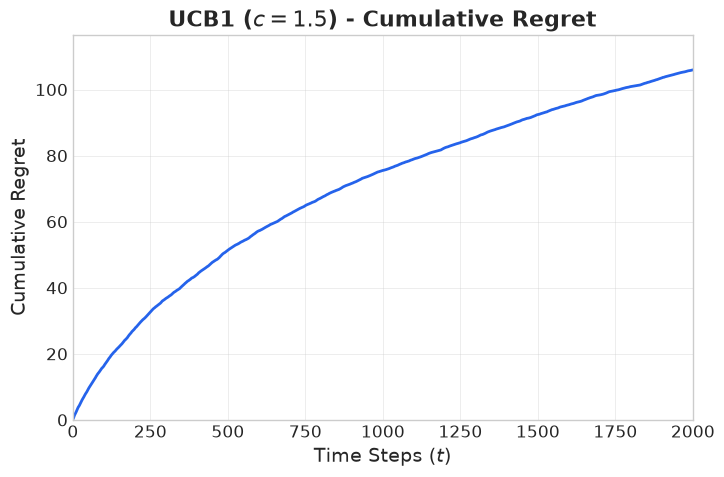

In [3]:
class UCB1Agent(BanditAgent):
    def __init__(self, n_arms, c=1.5):
        super().__init__(n_arms)
        self.c = c

    def select_action(self, step):
        if step < self.n_arms:
            return step
        exploration_term = self.c * np.sqrt(np.log(step) / self.counts)
        return np.argmax(self.q_values + exploration_term)

# Execute and Plot
regret_ucb = run_simulation(BernoulliBandit, UCB1Agent, {'c': 1.5}, STEPS, TRIALS)

plt.figure(figsize=(8, 5))
plt.plot(time_steps, regret_ucb, color='#2563eb', linewidth=2)
plt.title('UCB1 ($c=1.5$) - Cumulative Regret', fontweight='bold')
plt.xlabel('Time Steps ($t$)')
plt.ylabel('Cumulative Regret')
plt.xlim(0, STEPS)
plt.ylim(0, max(regret_ucb) * 1.1)
plt.savefig('algo_2_ucb1.png', dpi=300, bbox_inches='tight')
plt.show()

## Algorithm 3: Thompson Sampling Simulation
A Bayesian approach that samples expected rewards from a posterior Beta distribution, naturally tightening exploration as certainty increases.
$$\theta_a \sim \text{Beta}(\alpha_a, \beta_a)$$

Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.861)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.672)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.676)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.540)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.814)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.878)
Environment: 5 Arms | Optimal Arm: 3 (Prob: 0.835)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.814)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.882)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.875)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.501)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.717)
Environment: 5 Arms | Optimal Arm: 3 (Prob: 0.680)
Environment: 5 Arms | Optimal Arm: 1 (Prob: 0.692)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.878)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.796)
Environment: 5 Arms | Optimal Arm: 0 (Prob: 0.779)
Environment: 5 Arms | Optimal Arm: 2 (Prob: 0.541)
Environment: 5 Arms | Optimal Arm: 4 (Prob: 0.730)
Environment: 5 Arms | Optimal A

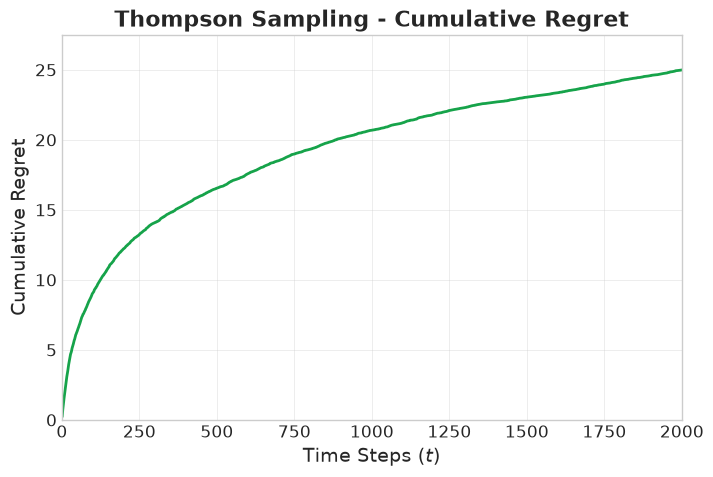

In [4]:
class ThompsonSamplingAgent(BanditAgent):
    def __init__(self, n_arms):
        super().__init__(n_arms)
        self.alpha = np.ones(n_arms)
        self.beta = np.ones(n_arms)

    def select_action(self, step):
        samples = np.random.beta(self.alpha, self.beta)
        return np.argmax(samples)

    def update(self, action, reward):
        super().update(action, reward)
        if reward == 1:
            self.alpha[action] += 1
        else:
            self.beta[action] += 1

# Execute and Plot
regret_ts = run_simulation(BernoulliBandit, ThompsonSamplingAgent, {}, STEPS, TRIALS)

plt.figure(figsize=(8, 5))
plt.plot(time_steps, regret_ts, color='#16a34a', linewidth=2)
plt.title('Thompson Sampling - Cumulative Regret', fontweight='bold')
plt.xlabel('Time Steps ($t$)')
plt.ylabel('Cumulative Regret')
plt.xlim(0, STEPS)
plt.ylim(0, max(regret_ts) * 1.1)
plt.savefig('algo_3_ts.png', dpi=300, bbox_inches='tight')
plt.show()

## Final Comparison & Performance Analysis
Aggregating the regret curves into a single chart to demonstrate the relative efficiency of deterministic and Bayesian exploration strategies over naive randomized exploration.

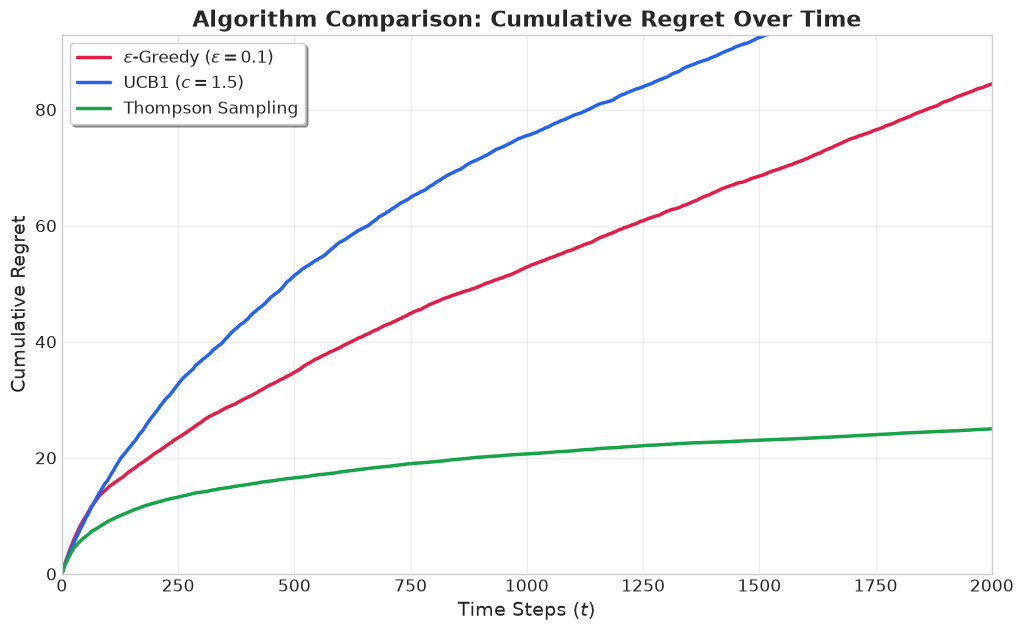

In [5]:
plt.figure(figsize=(12, 7))

plt.plot(time_steps, regret_eps, label=r'$\varepsilon$-Greedy ($\varepsilon=0.1$)', color='#e11d48', linewidth=2.5)
plt.plot(time_steps, regret_ucb, label='UCB1 ($c=1.5$)', color='#2563eb', linewidth=2.5)
plt.plot(time_steps, regret_ts, label='Thompson Sampling', color='#16a34a', linewidth=2.5)

plt.title('Algorithm Comparison: Cumulative Regret Over Time', fontweight='bold')
plt.xlabel('Time Steps ($t$)')
plt.ylabel('Cumulative Regret')
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.xlim(0, STEPS)
plt.ylim(0, max(regret_eps) * 1.1)

plt.savefig('cumulative_regret_comparison_final.png', dpi=300, bbox_inches='tight')
plt.show()

### Analytical Conclusion
*   **$\varepsilon$-Greedy (Red Line):** Exhibits a continuous linear accumulation of regret. The static $\varepsilon$ forces perpetual random sampling, preventing full exploitation of the optimal arm even after it has been identified.
*   **UCB1 (Blue Line):** Regret accumulation flattens logarithmically. The deterministic bounds aggressively eliminate suboptimal arms, proving high sample efficiency.
*   **Thompson Sampling (Green Line):** Achieves the lowest absolute regret. By continually updating a Bayesian posterior, it dynamically adapts to variance and transitions to exploitation faster than rigid statistical bounds.

**Final Verdict:** The simulation empirically validates the core claim of the survey: variance-aware and uncertainty-driven models (UCB1, Thompson Sampling) are strictly necessary for latency-constrained and cost-sensitive real-world environments compared to naive exploration.